# Heterogeneous-capacity α-matrix EDA

Focused analysis of the 30×30 experiments comparing `dmar_le` and `ca_dmar_r` across capacity profiles and α ∈ {0, 0.5, 1}.

The notebook checks data integrity, summarizes completion/rounds/movement, plots radius trends, and performs paired comparisons on identical scenarios.

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('.')
FILES = {
    'heterogeneous': DATA_DIR / 'benchmark-30x30-heterogeneous-capacity-alpha-matrix-5-tasks-per-agent-10-agents-dmar-le-ca.csv',
    'moderate-spread': DATA_DIR / 'benchmark-30x30-moderate-spread-capacity-alpha-matrix-5-tasks-per-agent-10-agents-dmar-le-ca.csv',
    'high-spread': DATA_DIR / 'benchmark-30x30-high-spread-capacity-alpha-matrix-5-tasks-per-agent-10-agents-dmar-le-ca.csv',
}
plt.style.use('seaborn-v0_8-whitegrid')


In [9]:
def load_csv(path):
    frame = pd.read_csv(path)
    frame['complete'] = frame['unresolved_tasks'].eq(0)
    frame['cap_hit'] = frame['rounds'].eq(5000)
    return frame

frames = []
for profile, path in FILES.items():
    if path.exists():
        frame = load_csv(path)
        frame['profile'] = profile
        frames.append(frame)
        print(profile, len(frame), 'rows')
    else:
        print('missing:', path)
df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
df.head()


heterogeneous 1440 rows
moderate-spread 1440 rows
high-spread 1440 rows


,algorithm,side,instance,run,sensing_radius,agent_count,task_count,task_agent_ratio,seed,movement_cost,...,max_cluster_size,unique_clustered_agents,rounds_with_clusters,cluster_dissolutions,exhausted_clustered_rounds,exhausted_agent_rounds,tasks_seen_by_exhausted_agents,complete,cap_hit,profile
0,dmar_le,30,0,0,1,10,50,1:5,3000000,10650,...,2,10,46,33,0,39350,4013,False,True,heterogeneous
1,ca_dmar_r,30,0,0,1,10,50,1:5,3000000,10650,...,2,10,46,33,0,39350,4013,False,True,heterogeneous
2,dmar_le,30,0,1,1,10,50,1:5,3000001,16421,...,1,10,47,35,0,33579,0,False,True,heterogeneous
3,ca_dmar_r,30,0,1,1,10,50,1:5,3000001,16421,...,1,10,47,35,0,33579,0,False,True,heterogeneous
4,dmar_le,30,0,2,1,10,50,1:5,3000002,7498,...,2,10,49,40,0,42502,4509,False,True,heterogeneous


## Integrity checks

In [10]:
print('rows:', len(df))
print('algorithms:', sorted(df['algorithm'].unique()))
print('alphas:', sorted(df['alpha'].unique()))
print('profiles:', sorted(df['profile'].unique()))
print('initial capacities:', sorted(df['initial_capacity'].unique()))
key = ['profile', 'algorithm', 'alpha', 'instance', 'run', 'sensing_radius']
print('duplicate scenario rows:', df.duplicated(key).sum())
df.groupby(['profile', 'alpha', 'algorithm']).size().unstack(fill_value=0)


rows: 4320
algorithms: ['ca_dmar_r', 'dmar_le']
alphas: [np.float64(0.0), np.float64(0.5), np.float64(1.0)]
profiles: ['heterogeneous', 'high-spread', 'moderate-spread']
initial capacities: [np.int64(54), np.int64(56), np.int64(73)]
duplicate scenario rows: 0


algorithm              ca_dmar_r  dmar_le
profile         alpha                    
heterogeneous   0.0          240      240
                0.5          240      240
                1.0          240      240
high-spread     0.0          240      240
                0.5          240      240
                1.0          240      240
moderate-spread 0.0          240      240
                0.5          240      240
                1.0          240      240

## Headline summary

In [11]:
summary = (df.groupby(['profile', 'alpha', 'algorithm'])
    .agg(runs=('complete', 'size'), completion=('complete', 'mean'),
         cap_hit=('cap_hit', 'mean'), mean_rounds=('rounds', 'mean'),
         mean_movement=('movement_cost', 'mean'),
         mean_unresolved=('unresolved_tasks', 'mean'))
    .reset_index())
summary['completion'] *= 100
summary['cap_hit'] *= 100
summary.round(2)


,profile,alpha,algorithm,runs,completion,cap_hit,mean_rounds,mean_movement,mean_unresolved
0,heterogeneous,0.0,ca_dmar_r,240,70.00,30.00,2972.03,5874.57,0.82
1,heterogeneous,0.0,dmar_le,240,69.17,31.25,3050.76,6147.99,1.17
2,heterogeneous,0.5,ca_dmar_r,240,67.50,32.50,3092.65,5887.02,0.91
3,heterogeneous,0.5,dmar_le,240,69.17,31.25,3050.76,6147.99,1.17
4,heterogeneous,1.0,ca_dmar_r,240,69.58,30.42,3072.18,5901.76,0.73
5,heterogeneous,1.0,dmar_le,240,69.17,31.25,3050.76,6147.99,1.17
6,high-spread,0.0,ca_dmar_r,240,95.42,4.58,1439.82,6093.08,0.05
7,high-spread,0.0,dmar_le,240,94.58,5.42,1547.34,6479.45,0.07
8,high-spread,0.5,ca_dmar_r,240,94.17,5.83,1553.80,6522.77,0.07
9,high-spread,0.5,dmar_le,240,94.58,5.42,1547.34,6479.45,0.07


## α sensitivity

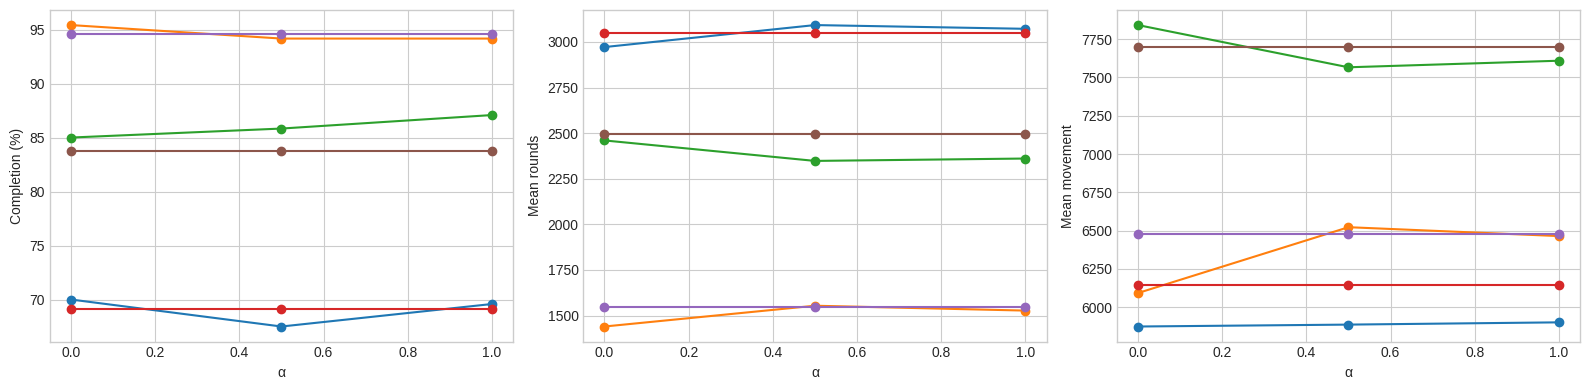

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, ylabel in zip(axes, ['complete', 'rounds', 'movement_cost'],
                              ['Completion (%)', 'Mean rounds', 'Mean movement']):
    plot = df.groupby(['profile', 'alpha', 'algorithm'])[metric].mean().reset_index()
    if metric == 'complete': plot[metric] *= 100
    for algorithm, group in plot.groupby('algorithm'):
        for profile, values in group.groupby('profile'):
            ax.plot(values['alpha'], values[metric], marker='o', label=f'{algorithm} / {profile}')
    ax.set_ylabel(ylabel)
    ax.set_xlabel('α')
plt.tight_layout()


## Completion by sensing radius

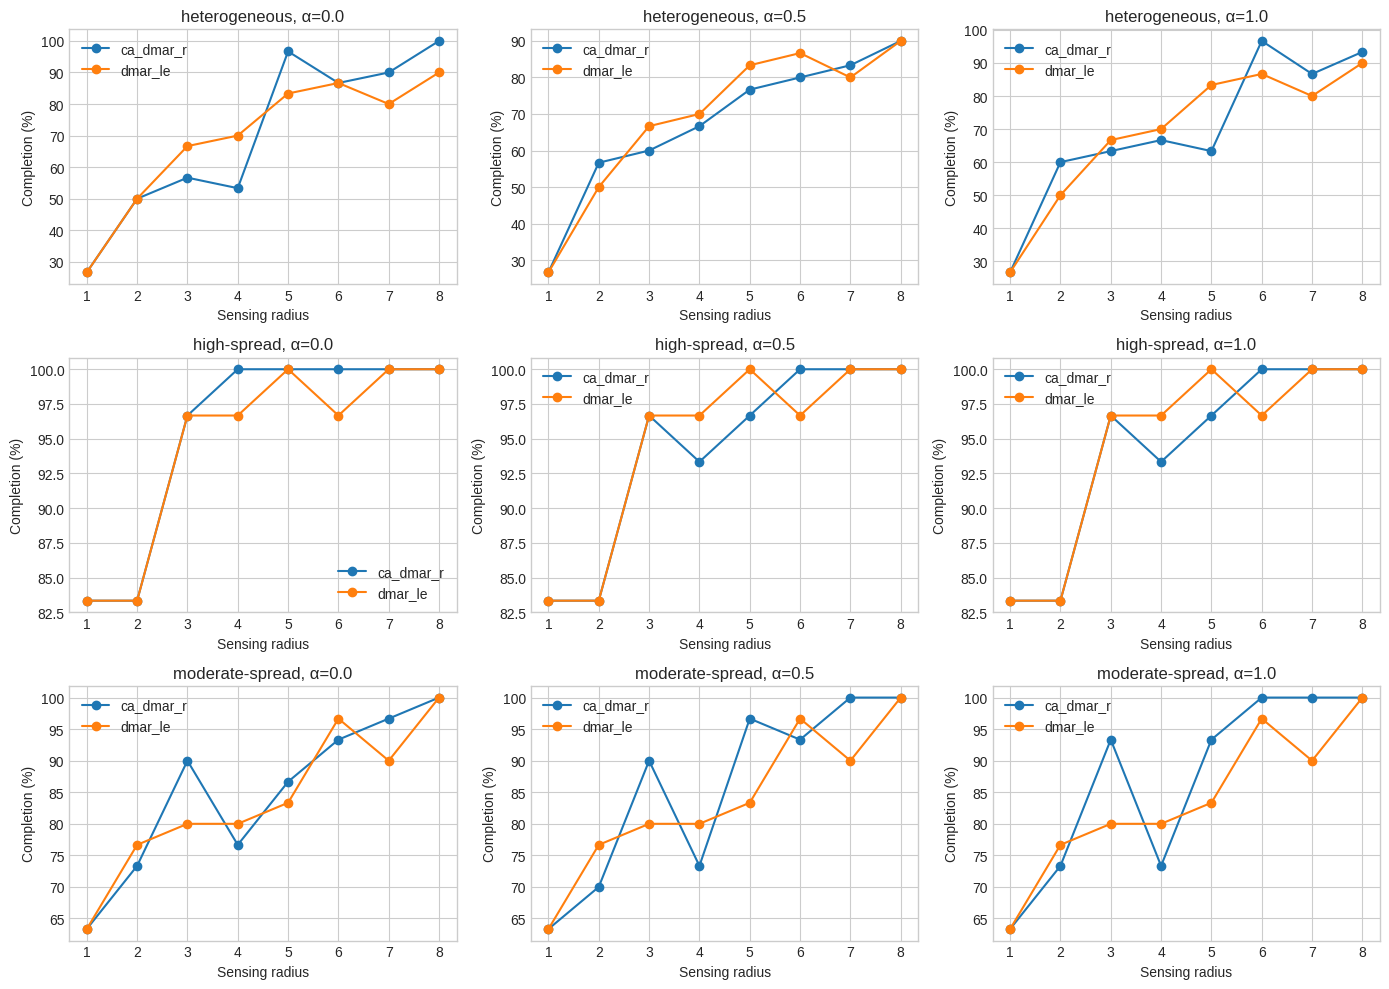

,profile,alpha,sensing_radius,algorithm,completion,rounds,movement
0,heterogeneous,0.0,1,ca_dmar_r,26.7,4547.2,10507.9
1,heterogeneous,0.0,1,dmar_le,26.7,4547.2,10507.9
2,heterogeneous,0.0,2,ca_dmar_r,50.0,3829.9,8120.7
3,heterogeneous,0.0,2,dmar_le,50.0,3834.9,7738.6
4,heterogeneous,0.0,3,ca_dmar_r,56.7,3533.2,6815.8
...,...,...,...,...,...,...,...
139,moderate-spread,1.0,6,dmar_le,96.7,1731.4,5159.5
140,moderate-spread,1.0,7,ca_dmar_r,100.0,1360.5,3863.1
141,moderate-spread,1.0,7,dmar_le,90.0,1793.8,4357.8
142,moderate-spread,1.0,8,ca_dmar_r,100.0,1569.1,4234.0


In [13]:
radius = (df.groupby(['profile', 'alpha', 'sensing_radius', 'algorithm'])
    .agg(completion=('complete', 'mean'), rounds=('rounds', 'mean'), movement=('movement_cost', 'mean'))
    .reset_index())
radius['completion'] *= 100
fig, axes = plt.subplots(len(radius['profile'].unique()), len(radius['alpha'].unique()), figsize=(14, 10), squeeze=False)
for (profile, alpha), values in radius.groupby(['profile', 'alpha']):
    row = list(sorted(radius['profile'].unique())).index(profile)
    col = list(sorted(radius['alpha'].unique())).index(alpha)
    ax = axes[row, col]
    for algorithm, group in values.groupby('algorithm'):
        ax.plot(group['sensing_radius'], group['completion'], marker='o', label=algorithm)
    ax.set_title(f'{profile}, α={alpha}')
    ax.set_xlabel('Sensing radius')
    ax.set_ylabel('Completion (%)')
    ax.legend()
plt.tight_layout()
plt.show()
radius.round(1)


## Paired CA-DMAR-R versus DMAR-LE

In [14]:
keys = ['profile', 'alpha', 'instance', 'run', 'sensing_radius']
wide = df.pivot_table(index=keys, columns='algorithm', values=['complete', 'rounds', 'movement_cost'])
paired = wide.dropna().copy()
paired['completion_difference_pp'] = 100 * (paired[('complete', 'ca_dmar_r')].astype(int) - paired[('complete', 'dmar_le')].astype(int))
paired['round_difference'] = paired[('rounds', 'ca_dmar_r')] - paired[('rounds', 'dmar_le')]
paired['movement_difference'] = paired[('movement_cost', 'ca_dmar_r')] - paired[('movement_cost', 'dmar_le')]
diff_table = pd.DataFrame({'profile': paired.index.get_level_values('profile'), 'alpha': paired.index.get_level_values('alpha'), 'completion_difference_pp': paired['completion_difference_pp'].to_numpy(), 'round_difference': paired['round_difference'].to_numpy(), 'movement_difference': paired['movement_difference'].to_numpy()})
diff_table.groupby(['profile', 'alpha'])[['completion_difference_pp', 'round_difference', 'movement_difference']].agg(['mean', 'median']).round(2)


completion_difference_pp        round_difference         \
                                          mean median             mean median   
profile         alpha                                                           
heterogeneous   0.0                       0.83    0.0           -78.73    0.0   
                0.5                      -1.67    0.0            41.89    0.0   
                1.0                       0.42    0.0            21.42    0.0   
high-spread     0.0                       0.83    0.0          -107.52    0.0   
                0.5                      -0.42    0.0             6.46    0.0   
                1.0                      -0.42    0.0           -20.25    0.0   
moderate-spread 0.0                       1.25    0.0           -33.78    0.0   
                0.5                       2.08    0.0          -146.05    0.0   
                1.0                       3.33    0.0          -132.99    0.0   

                      movement_difference         
                                     mean median  
profile         alpha                             
heterogeneous   0.0               -273.42    0.0  
                0.5               -260.96    0.0  
                1.0               -246.23    0.0  
high-spread     0.0               -386.37    0.0  
                0.5                 43.31    0.0  
                1.0                -14.63    0.0  
moderate-spread 0.0                146.30    0.0  
                0.5               -129.26    0.0  
                1.0                -86.34    0.0

## Interpretation

Use the tables to assess whether α changes CA-DMAR-R consistently. Since this is a paired experiment, compare the two algorithms on identical instance/run/radius keys. Small differences should not be called significant without confidence intervals or a paired statistical test. The results are sensitivity evidence, not a universal optimum for α.